<a href="https://colab.research.google.com/github/biglalo104/Projects/blob/main/Next%20Word%20Prediction%20and%20Sequence%20Tagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install nltk spacy scikit-learn transformers torch
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 21.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [5]:
import nltk
import math
import spacy
from nltk.util import ngrams
from nltk.probability import ConditionalFreqDist, ConditionalProbDist, LaplaceProbDist
from nltk.tokenize import word_tokenize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Download necessary NLTK data files
nltk.download('punkt')
nltk.download('punkt_tab')

# ==========================================
# DATASET PREPARATION
# ==========================================
# For this example, we use a small sample text.
# Tip: To use a Kaggle dataset, read it using pandas or standard file I/O:
# with open('your_dataset.txt', 'r', encoding='utf-8') as f:
#     text_data = f.read()

text_data = """
The cat sat on the mat. The dog barked at the cat.
Machine learning models are powerful. Machine learning algorithms learn from data.
Barack Obama was the 44th president of the USA. He visited New York in 2023.
"""

# ==========================================
# TASK 1: Language Modeling (Next Word Prediction)
# ==========================================
print("--- TASK 1: Language Modeling ---")

# 1. Preprocess text (tokenize and add start/end tokens for better context)
def preprocess(text):
    tokens = word_tokenize(text.lower())
    return ['<s>'] + tokens + ['</s>']

train_tokens = preprocess(text_data)

# 2. Build a Bigram Model with Laplace Smoothing (to avoid zero probabilities)
bigrams = list(ngrams(train_tokens, 2))
cfd = ConditionalFreqDist(bigrams)
# LaplaceProbDist adds a pseudocount of 1 to prevent 0% probabilities for unseen words
cpd = ConditionalProbDist(cfd, LaplaceProbDist)

# 3. Predict the next word
def predict_next_word(context, prob_dist, top_n=3):
    tokens = word_tokenize(context.lower())
    prev_word = tokens[-1]

    # Get probability distribution for the previous word
    dist = prob_dist[prev_word]
    # Sort samples by probability
    sorted_words = sorted(dist.samples(), key=lambda x: dist.prob(x), reverse=True)
    return sorted_words[:top_n]

# Test Predictions
print("Input: 'The cat' -> Predictions:", predict_next_word("The cat", cpd))
print("Input: 'Machine learning' -> Predictions:", predict_next_word("Machine learning", cpd))

# 4. Calculate Perplexity
def calculate_perplexity(test_text, prob_dist):
    test_tokens = preprocess(test_text)
    log_prob_sum = 0.0
    count = 0

    for i in range(1, len(test_tokens)):
        prev_word = test_tokens[i-1]
        curr_word = test_tokens[i]
        prob = prob_dist[prev_word].prob(curr_word)

        # Fallback for absolute zero probability (though Laplace prevents this)
        if prob == 0: prob = 1e-10
        log_prob_sum += math.log2(prob)
        count += 1

    perplexity = 2 ** (-log_prob_sum / count)
    return perplexity

test_sentence = "The cat sat on the mat."
perplexity = calculate_perplexity(test_sentence, cpd)
print(f"Model Perplexity on test sentence: {perplexity:.2f}\n")


# ==========================================
# TASK 2: Sequence Tagging (POS & NER)
# ==========================================
print("--- TASK 2: Sequence Tagging ---")

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")
tagging_text = "Barack Obama was the 44th president of the USA. He visited New York in 2023."
doc = nlp(tagging_text)

# 1. POS Tagging
print("POS Tagging:")
pos_tags = [(token.text, token.pos_) for token in doc]
for word, tag in pos_tags:
    print(f"{word}/{tag}", end=" ")
print("\n")

# 2. NER Tagging
print("NER Tagging:")
ner_tags = [(ent.text, ent.label_) for ent in doc.ents]
for entity, label in ner_tags:
    print(f"{entity}/{label}")
print()


# ==========================================
# TASK 3: Evaluation
# ==========================================
print("--- TASK 3: Evaluation ---")

# 1. Language Model Evaluation (Perplexity was calculated above)
print(f"Language Model Perplexity: {perplexity:.2f} (Lower is better)")

# 2. Sequence Tagging Evaluation
# Note: To calculate true metrics, you need a "Ground Truth" dataset.
# Here is an example of how to calculate it using mock ground truth vs predictions.

# Example POS Evaluation
y_true_pos = ["PROPN", "PROPN", "AUX", "DET", "ADJ", "NOUN", "ADP", "DET", "PROPN", "PUNCT"]
y_pred_pos = ["PROPN", "PROPN", "AUX", "DET", "NOUN", "NOUN", "ADP", "DET", "PROPN", "PUNCT"] # 1 error

pos_accuracy = accuracy_score(y_true_pos, y_pred_pos)
print(f"POS Tagging Accuracy: {pos_accuracy:.2f}")

# Example NER Evaluation (Token-level BIO format)
# B-PERSON (Begin Person), I-PERSON (Inside Person), B-GPE (Geo-Political Entity), O (Outside)
y_true_ner = ["B-PERSON", "I-PERSON", "O", "O", "O", "O", "O", "O", "B-GPE", "O"]
y_pred_ner = ["B-PERSON", "I-PERSON", "O", "O", "O", "O", "O", "O", "B-GPE", "O"]

ner_precision = precision_score(y_true_ner, y_pred_ner, average='weighted', zero_division=0)
ner_recall = recall_score(y_true_ner, y_pred_ner, average='weighted', zero_division=0)
ner_f1 = f1_score(y_true_ner, y_pred_ner, average='weighted', zero_division=0)

print(f"NER Precision: {ner_precision:.2f}")
print(f"NER Recall: {ner_recall:.2f}")
print(f"NER F1-Score: {ner_f1:.2f}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


--- TASK 1: Language Modeling ---
Input: 'The cat' -> Predictions: ['sat', '.']
Input: 'Machine learning' -> Predictions: ['models', 'algorithms']
Model Perplexity on test sentence: 1.96

--- TASK 2: Sequence Tagging ---
POS Tagging:
Barack/PROPN Obama/PROPN was/AUX the/DET 44th/ADJ president/NOUN of/ADP the/DET USA/PROPN ./PUNCT He/PRON visited/VERB New/PROPN York/PROPN in/ADP 2023/NUM ./PUNCT 

NER Tagging:
Barack Obama/PERSON
44th/ORDINAL
USA/GPE
New York/GPE
2023/DATE

--- TASK 3: Evaluation ---
Language Model Perplexity: 1.96 (Lower is better)
POS Tagging Accuracy: 0.90
NER Precision: 1.00
NER Recall: 1.00
NER F1-Score: 1.00


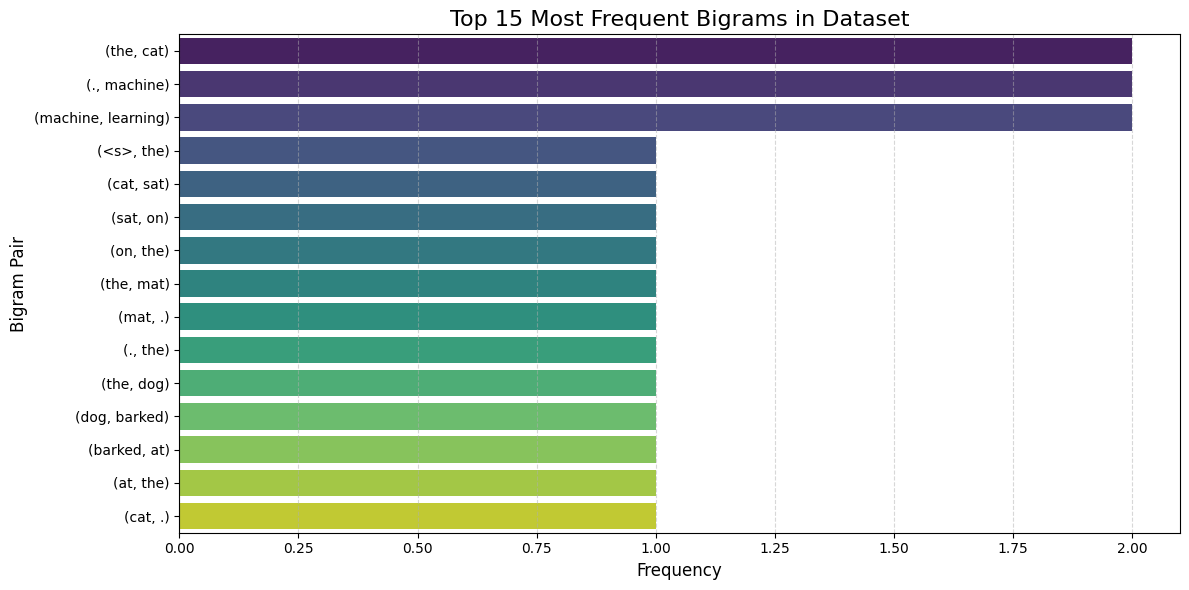

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Count the frequency of each bigram
bigram_counts = Counter(bigrams)

# Get the 15 most common bigrams
most_common_bigrams = bigram_counts.most_common(15)

# Format labels for the plot (e.g., "('the', 'cat')")
labels = [f"({bg[0]}, {bg[1]})" for bg, count in most_common_bigrams]
counts = [count for bg, count in most_common_bigrams]

# Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=labels, palette='viridis', hue=labels, legend=False)
plt.title('Top 15 Most Frequent Bigrams in Dataset', fontsize=16)
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Bigram Pair', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

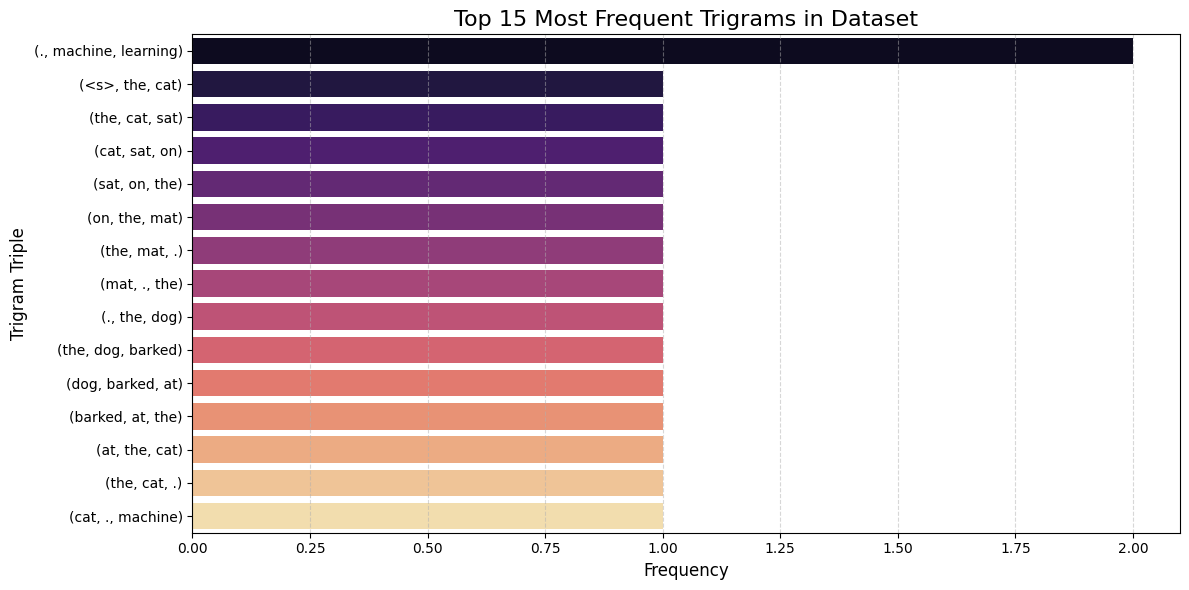

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.util import ngrams

# Generate trigrams from preprocessed tokens
trigrams = list(ngrams(train_tokens, 3))

# Count the frequency of each trigram
trigram_counts = Counter(trigrams)

# Get the 15 most common trigrams
most_common_trigrams = trigram_counts.most_common(15)

# Format labels for the plot
labels = [f"({tg[0]}, {tg[1]}, {tg[2]})" for tg, count in most_common_trigrams]
counts = [count for tg, count in most_common_trigrams]

# Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=labels, palette='magma', hue=labels, legend=False)
plt.title('Top 15 Most Frequent Trigrams in Dataset', fontsize=16)
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Trigram Triple', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [8]:
import nltk
from collections import Counter
from nltk.tokenize import word_tokenize
nltk.download('gutenberg')

# 1. Load a significantly larger corpus (Shakespeare's Hamlet from NLTK)
from nltk.corpus import gutenberg
raw_large_text = gutenberg.raw('shakespeare-hamlet.txt')

print(f"Loaded large dataset with {len(raw_large_text)} characters.")

# 2. Tokenize and count word frequencies to build a vocabulary
all_tokens = word_tokenize(raw_large_text.lower())
word_counts = Counter(all_tokens)

# 3. Define a vocabulary (keep words with frequency >= 3, treat others as <UNK>)
MIN_FREQ = 3
vocab = {word for word, count in word_counts.items() if count >= MIN_FREQ}

# 4. Preprocess text using the Vocabulary (replace low-frequency words with <UNK>)
processed_tokens = []
for token in all_tokens:
    if token in vocab:
        processed_tokens.append(token)
    else:
        processed_tokens.append('<UNK>')

print(f"Original Unique Tokens: {len(word_counts)}")
print(f"Vocabulary Size (min freq {MIN_FREQ}): {len(vocab)}")
print(f"First 50 processed tokens: {processed_tokens[:50]}")

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.


Loaded large dataset with 162881 characters.
Original Unique Tokens: 4790
Vocabulary Size (min freq 3): 1170
First 50 processed tokens: ['[', 'the', 'tragedie', 'of', 'hamlet', 'by', '<UNK>', '<UNK>', '<UNK>', ']', '<UNK>', '<UNK>', '.', '<UNK>', '<UNK>', '.', 'enter', 'barnardo', 'and', '<UNK>', 'two', '<UNK>', '.', 'barnardo', '.', 'who', "'s", 'there', '?', 'fran', '.', 'nay', 'answer', 'me', ':', 'stand', '&', 'vnfold', 'your', 'selfe', 'bar', '.', 'long', 'liue', 'the', 'king', 'fran', '.', 'barnardo', '?']


In [9]:
from nltk.util import ngrams
from nltk.probability import ConditionalFreqDist, ConditionalProbDist, LaplaceProbDist

# 1. Prepare bigrams and trigrams on the larger, preprocessed Hamlet text
processed_bigrams = list(ngrams(processed_tokens, 2))
processed_trigrams = list(ngrams(processed_tokens, 3))

# 2. Build Laplace-smoothed Conditional Probability Distributions
bigram_cfd = ConditionalFreqDist(processed_bigrams)
bigram_cpd = ConditionalProbDist(bigram_cfd, LaplaceProbDist)

print(f"Total processed bigrams: {len(processed_bigrams)}")
print(f"Distinct contexts (words) in bigram model: {len(bigram_cfd)}")

# 3. Predict next words on the scaled model
def predict_scaled(word, top_n=5):
    word_lower = word.lower()
    if word_lower not in vocab:
        word_lower = '<UNK>'
    dist = bigram_cpd[word_lower]
    sorted_words = sorted(dist.samples(), key=lambda x: dist.prob(x), reverse=True)
    return [(w, round(dist.prob(w), 4)) for w in sorted_words[:top_n]]

print("\nPredictions for 'the':", predict_scaled("the"))
print("Predictions for 'lord':", predict_scaled("lord"))
print("Predictions for an unseen word ('computer'):", predict_scaled("computer"))

Total processed bigrams: 36408
Distinct contexts (words) in bigram model: 1171

Predictions for 'the': [('<UNK>', 0.3021), ('king', 0.0325), ('matter', 0.0119), ('very', 0.0111), ('queene', 0.0111)]
Predictions for 'lord': [(',', 0.3096), ('ham', 0.1883), ('?', 0.1423), ('.', 0.0586), ('hamlet', 0.046)]
Predictions for an unseen word ('computer'): [(',', 0.152), ('<UNK>', 0.0886), ('of', 0.0507), ('.', 0.0427), (':', 0.0308)]


In [10]:
import random

def generate_sentence(start_word, length=20):
    current_word = start_word.lower() if start_word.lower() in vocab else '<UNK>'
    sentence = [current_word]

    for _ in range(length - 1):
        dist = bigram_cpd[current_word]
        # Draw a sample token based on the smoothed probability distribution
        choices = list(dist.samples())
        probabilities = [dist.prob(word) for word in choices]

        # Choose next word
        next_word = random.choices(choices, weights=probabilities, k=1)[0]
        sentence.append(next_word)
        current_word = next_word

    return " ".join(sentence)

# Generate sample sentences starting with different words
print("Generated sentence 1:", generate_sentence("The", length=15))
print("Generated sentence 2:", generate_sentence("Lord", length=15))
print("Generated sentence 3:", generate_sentence("Hamlet", length=15))

Generated sentence 1: the <UNK> shadow of our owne <UNK> , and <UNK> thus wide ile change rapiers
Generated sentence 2: lord . if you faire houre of <UNK> into <UNK> . with that certaine players
Generated sentence 3: hamlet <UNK> <UNK> of thought i stand , and for the <UNK> in polonius ,
